# Interstellar plasma geometry from measured interference

Eight real Parkes/CASPSR intensity spectra of PSRJ0437−4715 on2011-12-20 are actively inverted. All512channels and all121/122native integrations are loaded; the original leading-short-exposure and edge rules run here, followed by explicitly extracted biharmonic gap equations, rank-one gain estimation, wavelength resampling and normalized arc-power fitting. All eight individual measurements and the all-eight concatenation are reconstructed.

The unknown is κ=De/Vparallel², in s²/m. De=D s(1−s) is the effective geometric distance, with source distance D and source-to-observer fractional screen coordinate s; Vparallel is effective transverse velocity along the relevant scattering direction. They cannot be separated using this track alone. The thin-screen relation is

$$
\beta=\frac{c\tau}{\lambda^2}=\frac{\kappa}{2}f_{\mathrm{Hz}}^2.
$$

β is the nonnegative wavelength-conjugate coordinate incycles/m, τ is geometric delay, λ is wavelength and f is cyclic Doppler frequency. The original fitted coefficient usesmHz, so κ=2×10⁶ηβ. There is no extra2π. The mean-subtracted/tapered intensity's squared2D Fourier magnitude reveals the arc; row-wise Doppler resampling straightens trial parabolas and a quadratic fit estimates the concentrated power peak. The author current example protocol is reproduced; its Hann/no-prewhitening defaults differ from some settings described in the paper, as recorded in the plans.

The reproduced original runs are comparisons, not actual screen-distance truth. The primary curvature/empirical-noise paths retain source mathematics. A separate legacy parabola coefficient-error formula is known incorrect and is explicitly compared with a corrected covariance diagnostic below; that correction does not alter the primary reconstruction.

In [1]:
from pathlib import Path
import os,sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
TASK=Path.cwd()
if not (TASK/'src').exists():TASK=TASK.parent
os.chdir(TASK);sys.path.insert(0,str(TASK))
from src.solvers import reconstruct
from src.visualization import secondary_image
start=time.perf_counter();fresh,diagnostics,record=reconstruct();elapsed=time.perf_counter()-start
np.savez('output/reconstruction.npz',reconstruction=fresh)
spec=importlib.util.spec_from_file_location('independent_judge',TASK/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(TASK/'output/reconstruction.npz');assert report['passed'],report
with np.load('notebooks/reference_outputs/upstream_measurements.npz') as f:upstream={k:f[k] for k in f.files}
empirical=2e6*np.array([d.betaetaerr for d in diagnostics])
corrected=2e6*np.array([d.parabola_standard_error for d in diagnostics])
np.savez('notebooks/reference_outputs/fresh_measurements.npz',reconstruction=fresh,empirical_error=empirical[None],corrected_parabola_error=corrected[None])
with np.load('data/raw_data.npz') as f:raw={k:f[k] for k in f.files}
print('Python executable:',sys.executable)
print('Fresh full eight-plus-stitched elapsed seconds:',elapsed)
print('All native shapes:',[raw[f'intensity_{i}'].shape for i in range(8)])
print('Prepared segment shapes:',[d.dyn.shape for d in diagnostics[:8]])
print('All fresh κ (s²/m):',fresh)
print('Independent Judge:',json.dumps(report,indent=2))
print('Maximum source/fresh relative κ discrepancy:',np.max(abs(fresh-upstream['reconstruction'])/upstream['reconstruction']))

Python executable: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe
Fresh full eight-plus-stitched elapsed seconds: 1.1084613000275567
All native shapes: [(1, 512, 122), (1, 512, 121), (1, 512, 122), (1, 512, 122), (1, 512, 121), (1, 512, 121), (1, 512, 121), (1, 512, 121)]
Prepared segment shapes: [(398, 121), (398, 120), (398, 121), (398, 121), (398, 120), (398, 121), (398, 120), (398, 121)]
All fresh κ (s²/m): [[1.26120195e+08 1.28299448e+08 1.27950076e+08 1.26157603e+08
  1.32217097e+08 1.31247087e+08 1.30536756e+08 1.32697470e+08
  1.27990522e+08]]
Independent Judge: {
  "status": "pass",
  "passed": true,
  "metrics": {
    "maximum_kappa_relative_error": 1.9090020282790393e-15,
    "maximum_power_deficit_db": 0.29515963503895115
  },
  "thresholds": {
    "maximum_kappa_relative_error": {
      "comparison": "<=",
      "boundary": 0.01
    },
    "maximum_power_deficit_db": {
      "comparison": "<=",
      "boundary": 0.5
    }
  },
  "errors"

## Native data and the active processing stages

The first image contains every native integration, including the short leading exposure and flagged bands. The prepared intensity is computed by solving the discrete reflecting-boundary biharmonic equation on flagged samples, then estimating and dividing by the observed first singular mode. Frequency- and wavelength-conjugate secondary spectra below are both freshly computed. The wavelength-domain arc overlay uses the recovered physical κ; it is not a hidden calibration. Display color limits follow the source's median/maxdB convention and do not modify any array or metric.

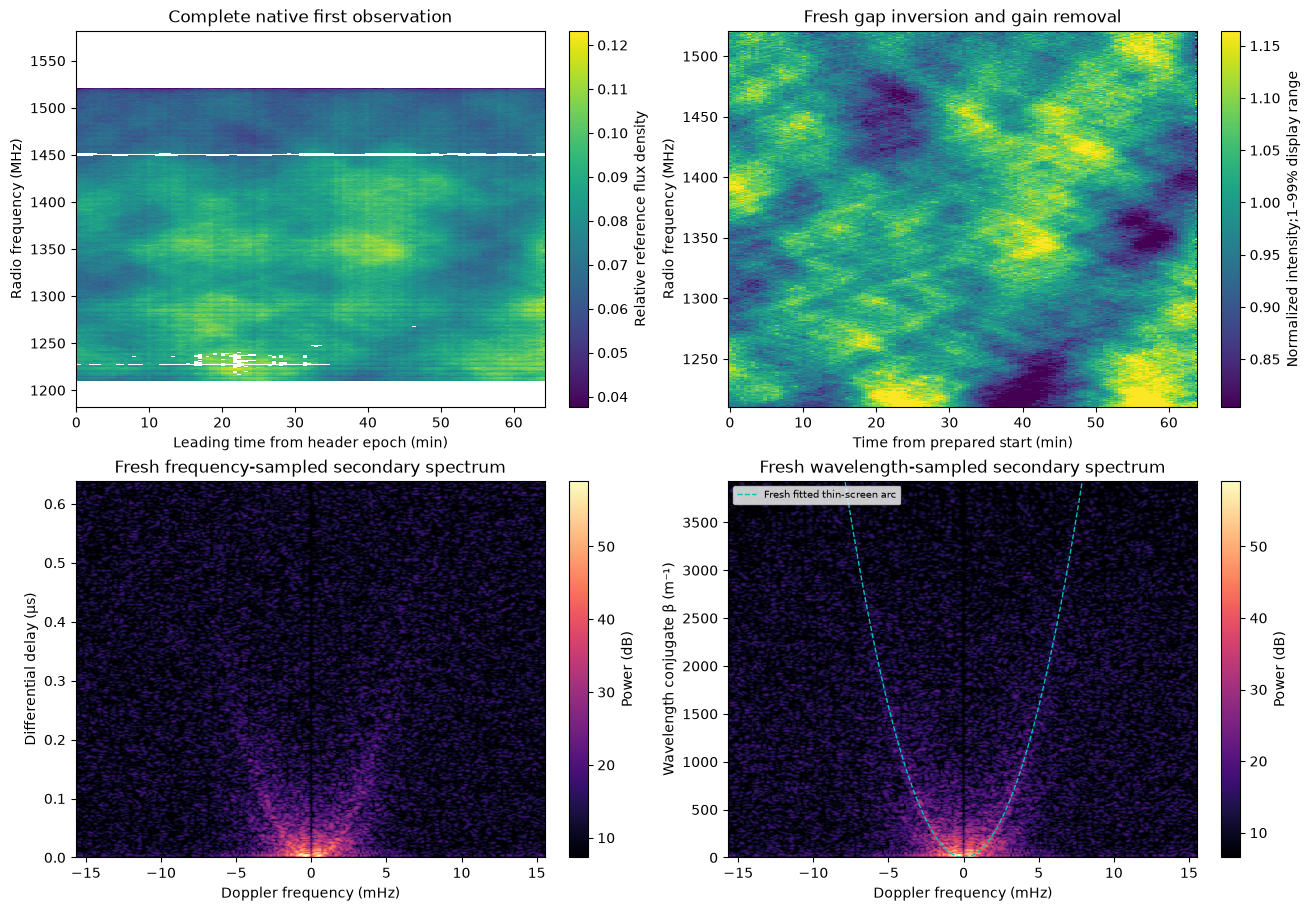

In [2]:
d=diagnostics[0]
fig,axes=plt.subplots(2,2,figsize=(13,9),layout='constrained')
native=np.ma.masked_where(raw['intensity_0'][0]==0,raw['intensity_0'][0])
im=axes[0,0].pcolormesh(raw['time_0'][0]/60,raw['frequency_0'][0],native,shading='auto',cmap='viridis')
axes[0,0].set(xlabel='Leading time from header epoch (min)',ylabel='Radio frequency (MHz)',title='Complete native first observation')
fig.colorbar(im,ax=axes[0,0],label='Relative reference flux density')
im=axes[0,1].pcolormesh(d.times/60,d.freqs,d.dyn,shading='auto',cmap='viridis',vmin=np.percentile(d.dyn,1),vmax=np.percentile(d.dyn,99))
axes[0,1].set(xlabel='Time from prepared start (min)',ylabel='Radio frequency (MHz)',title='Fresh gap inversion and gain removal')
fig.colorbar(im,ax=axes[0,1],label='Normalized intensity;1–99% display range')
im=secondary_image(axes[1,0],d,False);axes[1,0].set_title('Fresh frequency-sampled secondary spectrum');fig.colorbar(im,ax=axes[1,0],label='Power (dB)')
im=secondary_image(axes[1,1],d,True);axes[1,1].set_title('Fresh wavelength-sampled secondary spectrum');fig.colorbar(im,ax=axes[1,1],label='Power (dB)')
fig.savefig('output/scintools_processing.png',dpi=150);plt.show()

## Actual observing-span comparison: eight short spectra and their concatenation

This is the author example's physical comparison: increasing the observing span resolves finer Doppler structure while preserving measured gaps and clock conventions. The full concatenation is fitted again, rather than averaged from the eight parameter estimates. All nine outputs participate in evaluation. The source empirical errors are noise/peak-width diagnostics, not actual distance confidence intervals. The original approximation that retains the first frequency/FFT clock calibration is documented; rounded inter-segment channel offsets are below0.000854MHz, far below one channel.

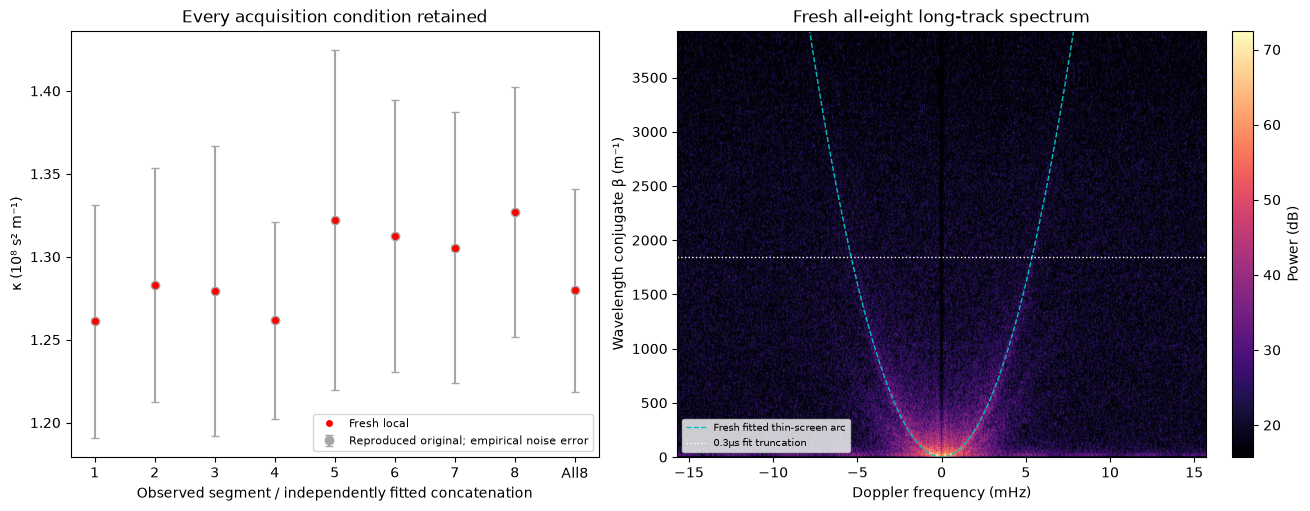

Short segment spans (s): [np.float64(3857.389), np.float64(3834.787), np.float64(3862.187), np.float64(3856.379), np.float64(3839.101), np.float64(3866.791), np.float64(3839.833), np.float64(3867.765)]
Combined span (s): 32667.732
Nine source empirical errors (s²/m): [ 7028915.62923071  7028915.62923071  8755987.86540232  5919357.68949587
 10246205.84630973  8178098.79905878  8178098.79905878  7525981.7677634
  6122602.74845207]


In [3]:
fig,axes=plt.subplots(1,2,figsize=(13,5),layout='constrained')
x=np.arange(9)
axes[0].errorbar(x,upstream['reconstruction'][0]/1e8,yerr=upstream['empirical_error'][0]/1e8,fmt='o',color='.65',capsize=3,label='Reproduced original; empirical noise error')
axes[0].plot(x,fresh[0]/1e8,'r.',ms=8,zorder=5,label='Fresh local')
axes[0].set_xticks(x,[str(i+1) for i in range(8)]+['All8'])
axes[0].set(xlabel='Observed segment / independently fitted concatenation',ylabel='κ (10⁸ s² m⁻¹)',title='Every acquisition condition retained');axes[0].legend(fontsize=8)
im=secondary_image(axes[1],diagnostics[-1],True)
axes[1].set_title('Fresh all-eight long-track spectrum')
fit_index=np.argmin(abs(diagnostics[-1].tdel-.3))
axes[1].axhline(diagnostics[-1].beta[fit_index],color='white',ls=':',lw=1,label='0.3μs fit truncation')
axes[1].legend(fontsize=7);fig.colorbar(im,ax=axes[1],label='Power (dB)')
fig.savefig('output/scintools_span.png',dpi=150);plt.show()
print('Short segment spans (s):',[d.tobs for d in diagnostics[:8]])
print('Combined span (s):',diagnostics[-1].tobs)
print('Nine source empirical errors (s²/m):',upstream['empirical_error'][0])

## Measured power agreement and the investigated auxiliary error discrepancy

All eight power profiles are displayed, followed by the separately reconstructed long-track profile. Original measurements and fresh calculations are identified independently. Each curve is normalized only for display to its own measured maximum; evaluation uses unshifted profiles.

For a fitted quadratic y=a x²+b x+c, the curvature peak is p=−b/(2a). Correct propagation through its coefficient covariance C uses J=[b/(2a²),−1/(2a),0] and σp²=J C Jᵀ, with the source coordinate scaling explicitly undone. The original auxiliary formula omits powers of a and cross covariance. Its additional√2 division is also omitted from the corrected diagnostic because C already describes the fitted symmetric profile. The legacy values below are historical uncorrected outputs, not validated uncertainty. This intentional auxiliary correction is not described as unchanged reproduction; primary κ and the separate original empirical-noise error are preserved.

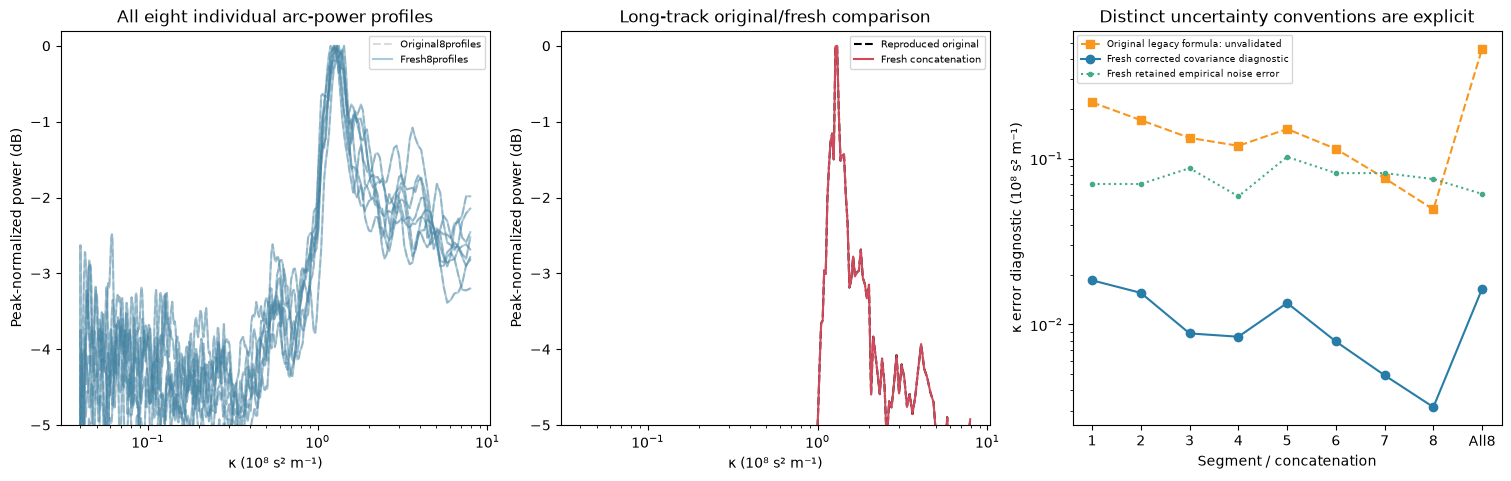

Fresh corrected covariance diagnostics: [1844889.96106749 1550491.25017275  882837.60138166  842911.65520906
 1347484.97852646  789183.33117995  493567.22044759  317191.34980891
 1643854.45315492]
Primary result passes: True
These observations constrain the effective combination κ, not separate screen distances or velocities. Conditional source agreement is not proof of physical accuracy.


In [4]:
fig,axes=plt.subplots(1,3,figsize=(15,4.7),layout='constrained')
for i,d in enumerate(diagnostics[:8]):
    grid=upstream[f'curvature_grid_{i}']*2e6/1e8;power=upstream[f'observed_power_{i}']
    axes[0].plot(grid,power-power.max(),'--',color='.6',alpha=.35,label='Original8profiles' if i==0 else None)
    axes[0].plot(d.eta_array*2e6/1e8,d.norm_sspec_avg-np.max(d.norm_sspec_avg),color='#277da8',alpha=.4,label='Fresh8profiles' if i==0 else None)
d=diagnostics[-1];power=upstream['observed_power_8']
axes[1].plot(upstream['curvature_grid_8']*2e6/1e8,power-power.max(),'k--',label='Reproduced original')
axes[1].plot(d.eta_array*2e6/1e8,d.norm_sspec_avg-np.max(d.norm_sspec_avg),color='#d1495b',label='Fresh concatenation')
for ax,title in zip(axes[:2],['All eight individual arc-power profiles','Long-track original/fresh comparison']):
    ax.set(xscale='log',xlabel='κ (10⁸ s² m⁻¹)',ylabel='Peak-normalized power (dB)',title=title);ax.legend(fontsize=7)
    ax.set_ylim(-5,.2)
axes[2].plot(x,upstream['legacy_parabola_error'][0]/1e8,'s--',label='Original legacy formula: unvalidated',color='#f8961e')
axes[2].plot(x,corrected/1e8,'o-',label='Fresh corrected covariance diagnostic',color='#277da8')
axes[2].plot(x,empirical/1e8,'.:',label='Fresh retained empirical noise error',color='#43aa8b')
axes[2].set_xticks(x,[str(i+1) for i in range(8)]+['All8'])
axes[2].set(xlabel='Segment / concatenation',ylabel='κ error diagnostic (10⁸ s² m⁻¹)',yscale='log',title='Distinct uncertainty conventions are explicit');axes[2].legend(fontsize=6.7)
fig.savefig('output/scintools_profiles.png',dpi=150);plt.show()
print('Fresh corrected covariance diagnostics:',corrected)
print('Primary result passes:',report['passed'])
print('These observations constrain the effective combination κ, not separate screen distances or velocities. Conditional source agreement is not proof of physical accuracy.')